In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if not (root / "src" / "utils_cv.py").exists():
    root = root.parent

sys.path.insert(0, str(root / "src"))


# Kode 4.1 Verifikasi konvolusi manual 

In [2]:
import time 
import cv2
import numpy as np
from utils_cv import baca, kontras_bercak
  
def konvolusi(img, k):            # fungsi dari slide P4 
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2 
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge") 
    out = np.zeros(img.shape) 
    for y in range(img.shape[0]): 
        for x in range(img.shape[1]): 
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k) 
    return np.clip(np.round(out), 0, 255).astype(np.uint8) 
  
def konvolusi_sejati(img, k):     # kernel dibalik 180 derajat dahulu 
    return konvolusi(img, np.flip(k)) 
  
nama = "teh_041.png" 
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), 
                      cv2.COLOR_BGR2GRAY) 
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0) 
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0) 
  
for nm, k in {"rerata": np.ones((3, 3)) / 9, 
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float) 
              }.items(): 
    t0 = time.perf_counter(); a = konvolusi(bersih, k) 
    t_manual = time.perf_counter() - t0 
    t0 = time.perf_counter() 
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE) 
    t_cv = time.perf_counter() - t0 
    beda = np.abs(a.astype(int) - b.astype(int)).max() 
    c = konvolusi_sejati(bersih, k) 
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, " 
          f"sejati vs filter2D={beda2}, " 
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=3.964 s, filter2D=0.00128 s


asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=3.092 s, filter2D=0.00034 s


# Kode 4.2 Tabel penapis x derau x PSNR x waktu x KB 

In [3]:
import pandas as pd 
rng = np.random.default_rng(1063) 
  
def derau_gauss(img, sd): 
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8) 
  
def derau_sp(img, p):                  # p = proporsi piksel rusak 
    out = img.copy(); m = rng.random(img.shape) 
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255 
    return out 
  
def ukur_waktu(f, x, ulang=20):        # rerata beberapa kali, dalam ms 
    t = [] 
    for _ in range(ulang): 
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0) 
    return 1000 * np.mean(t) 
  
derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 
20), 
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04), 
         "sp_10%": derau_sp(bersih, 0.10)} 
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)), 
           "rerata_5": lambda x: cv2.blur(x, (5, 5)), 
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0), 
           "median_3": lambda x: cv2.medianBlur(x, 3), 
           "median_5": lambda x: cv2.medianBlur(x, 5), 
           "median_9": lambda x: cv2.medianBlur(x, 9)} 
baris = [] 
for dn, d in derau.items(): 
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, 
                  kontras_bercak(d, md, mb)]) 
    for pn, f in penapis.items(): 
        out = f(d) 
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d), 
                      kontras_bercak(out, md, mb)]) 
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", 
                                     "waktu_ms", "KB"]).round(2) 
print(tabel) 
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False) 


       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  2.35
1   gauss_10  rerata_3    37.05      0.59  3.93
2   gauss_10  rerata_5    38.59      0.58  4.30
3   gauss_10   gauss_5    37.99      0.34  4.07
4   gauss_10  median_3    35.52      0.09  3.77
5   gauss_10  median_5    38.49      2.36  4.37
6   gauss_10  median_9    38.92     18.05  4.94
7   gauss_20     tanpa    22.11      0.00  1.32
8   gauss_20  rerata_3    31.49      0.57  3.03
9   gauss_20  rerata_5    34.93      1.54  3.76
10  gauss_20   gauss_5    32.67      0.55  3.26
11  gauss_20  median_3    29.78      0.36  2.72
12  gauss_20  median_5    33.51      2.33  3.59
13  gauss_20  median_9    35.89     27.42  4.20
14  gauss_40     tanpa    16.29      0.00  0.71
15  gauss_40  rerata_3    25.76      0.63  1.98
16  gauss_40  rerata_5    29.88      0.54  2.87
17  gauss_40   gauss_5    26.99      0.16  2.22
18  gauss_40  median_3    23.84      0.14  1.70
19  gauss_40  median_5    27.95      0.9

# Kode 4.3 Pengaruh ukuran kernel median pada bercak kecil 

In [4]:
def selisih_rerata(kanal, mask_daun, mask_bercak): 
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas.""" 
    k = kanal.astype(float) 
    sehat = (mask_daun > 0) & (mask_bercak == 0) 
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean()) 
  
label = pd.read_csv("../data/sintetis/label.csv") 
baris = [] 
for nm in label[label.kelas == "ringan"].nama_file: 
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY) 
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0) 
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0) 
    for k in [1, 3, 5, 9, 15]:          # k = 1 berarti tanpa penapis 
        out = g if k == 1 else cv2.medianBlur(g, k) 
        baris.append([nm, k, selisih_rerata(out, md2, mb2), 
                      kontras_bercak(out, md2, mb2)]) 
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"]) 
print(hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)) 

           dI    KB
kernel             
1       26.23  4.11
3       26.41  4.21
5       24.97  4.03
9       17.18  3.16
15       5.12  1.32


# Kode 4.4 Pengaruh urutan penajaman 

In [5]:
def unsharp(x, k=1.0): 
    blur = cv2.GaussianBlur(x, (5, 5), 1.0) 
    return cv2.addWeighted(x, 1 + k, blur, -k, 0) 
  
noisy = derau["gauss_20"] 
latar = md == 0                         # area latar yang seharusnya rata 
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0), 
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items(): 
    A = redam(unsharp(noisy))           # tajamkan dulu, lalu redam 
    B = unsharp(redam(noisy))           # redam dulu, lalu tajamkan 
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} " 
          f"sigma_latar={A[latar].std():.1f} | redam->tajam " 
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}") 

Gaussian: tajam->redam PSNR=30.35 sigma_latar=7.9 | redam->tajam PSNR=30.24 sigma_latar=8.0
Median: tajam->redam PSNR=30.18 sigma_latar=7.9 | redam->tajam PSNR=31.15 sigma_latar=7.1


# Kode 4.3 Grafik PSNR dan waktu


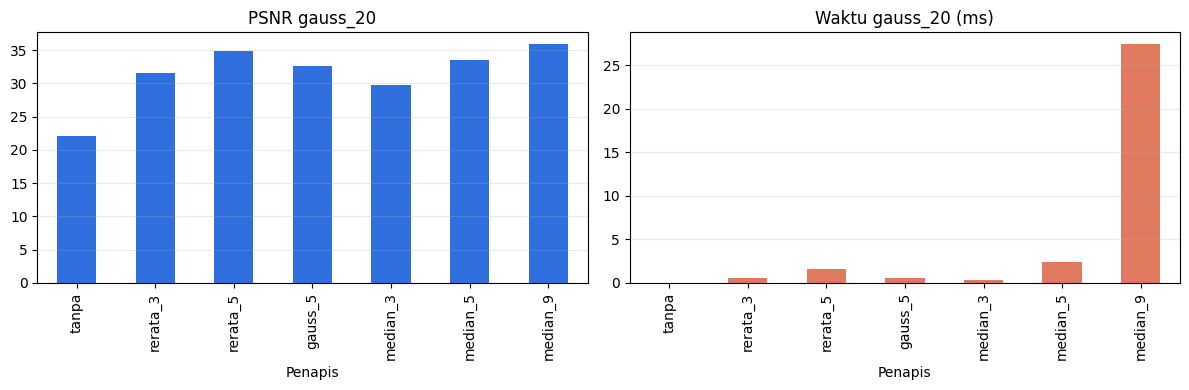

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

if "tabel" not in globals():
    tabel = pd.read_csv(Path("../hasil/b4_tabel_penapis.csv"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for label, sub in tabel[tabel.derau == "gauss_20"].groupby("derau"):
    sub.plot.bar(x="penapis", y="PSNR_dB", ax=ax[0], legend=False, color="#2f6fde")
    sub.plot.bar(x="penapis", y="waktu_ms", ax=ax[1], legend=False, color="#e07a5f")
ax[0].set_title("PSNR gauss_20"); ax[1].set_title("Waktu gauss_20 (ms)")
for a in ax: a.set_xlabel("Penapis"); a.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.savefig("../hasil/b4_psnr_waktu.png", dpi=150); plt.show()


# Kode 4.4 Grafik dI dan crop bercak


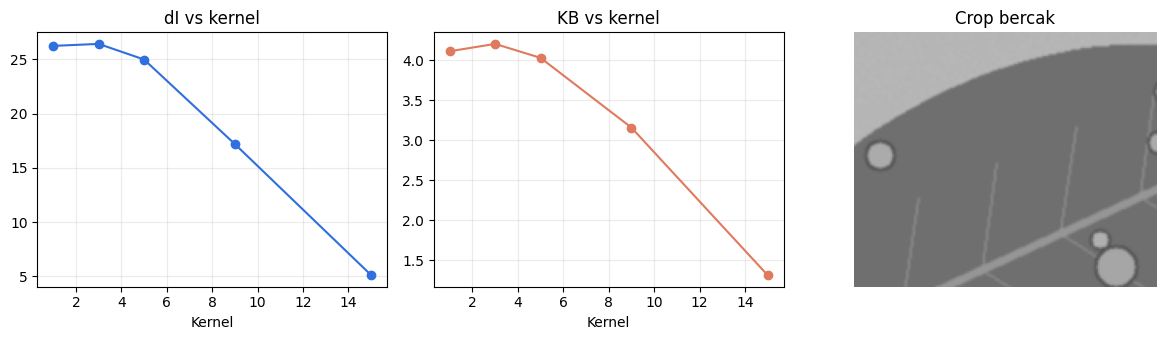

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
sub = hasil_median.groupby("kernel")[["dI", "KB"]].mean()
sub.plot(y="dI", marker="o", ax=ax[0], legend=False, color="#2f6fde"); ax[0].set_title("dI vs kernel")
sub.plot(y="KB", marker="o", ax=ax[1], legend=False, color="#e07a5f"); ax[1].set_title("KB vs kernel")
crop = bersih[140:300, 240:430]; ax[2].imshow(crop, cmap="gray", vmin=0, vmax=255); ax[2].set_title("Crop bercak"); ax[2].axis("off")
for a in ax[:2]: a.set_xlabel("Kernel"); a.grid(alpha=.25)
plt.tight_layout(); plt.savefig("../hasil/b4_di_bercak.png", dpi=150); plt.show()


# Kode 4.6 PSNR normal sebelum/sesudah


In [8]:
psnr_rows = []
for nm in ["teh_001.png", "teh_006.png", "teh_011.png", "teh_016.png", "teh_021.png", "teh_026.png", "teh_031.png", "teh_036.png", "teh_041.png", "teh_046.png", "teh_051.png", "teh_056.png"]:
    asli = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    acuan = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    sesudah = cv2.medianBlur(asli, 3)
    psnr_rows.append([nm, cv2.PSNR(acuan, asli), cv2.PSNR(acuan, sesudah)])
psnr_normal = pd.DataFrame(psnr_rows, columns=["Citra", "PSNR sebelum (dB)", "PSNR sesudah (dB)"])
psnr_normal["Selisih (dB)"] = psnr_normal.iloc[:,2] - psnr_normal.iloc[:,1]
psnr_normal.to_csv("../hasil/b4_psnr_normal.csv", index=False); print(psnr_normal.round(2))


          Citra  PSNR sebelum (dB)  PSNR sesudah (dB)  Selisih (dB)
0   teh_001.png              32.94              40.00          7.05
1   teh_006.png              30.88              38.10          7.23
2   teh_011.png              32.47              39.62          7.14
3   teh_016.png              30.90              38.13          7.23
4   teh_021.png              30.82              38.04          7.21
5   teh_026.png              31.47              38.68          7.21
6   teh_031.png              31.17              38.39          7.22
7   teh_036.png              30.21              37.54          7.34
8   teh_041.png              30.24              37.53          7.29
9   teh_046.png              32.42              39.39          6.97
10  teh_051.png              30.22              37.41          7.19
11  teh_056.png              29.50              36.73          7.23


## Grafik PSNR dan waktu
![Grafik PSNR dan waktu](../hasil/b4_psnr_waktu.png)


## Grafik dI dan crop bercak
![Grafik dI dan crop bercak](../hasil/b4_di_bercak.png)
